AI acknowledgement: I used AI to assist with computing the spectra in question 3, particularly with getting a correct normalization. I additionally used it to help with making the tables look nice in question 2.

# Question 1

In [139]:
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass, field
import os
from netCDF4 import Dataset
import pandas as pd
import xarray as xr
from scipy.signal import detrend
from scipy.stats import chi2 as chi2_dist
from tabulate import tabulate
from IPython.display import display, Markdown

In [112]:
@dataclass
class PierData:
    """A slice of the 2021 pier record. """
    dnum: np.ndarray          # times, as numpy datetime64[s]
    temperature: np.ndarray   # degrees C
    pressure: np.ndarray      # decibars
    readme: str = field(
        default='2021 Pier data, SIO221a, function get_2021_pier_data.py')

    def __len__(self):
        return len(self.dnum)

    
def get_pier_data(file, date_start=None, date_end=None):
    """Return temperature, pressure and time from the 2020 Scripps pier record.

    Parameters
    ----------
    date_start, date_end : numpy datetime64 or str, optional
        Bracket the period you want, e.g. '2020-06-04'.  Omit both to get the
        whole record.
    file : str, optional
        Path to the netCDF file.  Omit it and we find data/scripps_pier-2020.nc
        inside the class repo.

    Returns
    -------
    pier : PierData
    """

    nc = Dataset(file)
    try:
        time = np.asarray(nc.variables['time'][:])
        temperature = np.asarray(nc.variables['temperature'][:])
        pressure = np.asarray(nc.variables['pressure'][:])
    finally:
        nc.close()

    # netCDF time is seconds since 1970-01-01, which is exactly datetime64[s].
    dnum = time.astype('datetime64[s]')

    if date_start is None:
        i1 = np.ones(dnum.shape, dtype=bool)
    else:
        i1 = ((dnum > np.datetime64(date_start)) &
              (dnum < np.datetime64(date_end)))

    return PierData(dnum=dnum[i1],
                    temperature=temperature[i1],
                    pressure=pressure[i1])


def getManyPier(numyears, start, date_start=None, date_end=None):
    """
    converts from pier object to dictionary in order to append more easily

    takes in number of years to add together, starting year

    returns: PierData object 
    
    """
    pier_data = {"dnum":np.array([], dtype='datetime64[s]'), "temperature":np.array([]), "pressure":np.array([])} #make an initial dictionary to append all the data to
    for i in range(start,start+numyears):
        pier = get_pier_data(file= "../pier_data/scripps_pier-"+str(i)+".nc")
        pier_data["dnum"] = np.concatenate((pier_data["dnum"], pier.dnum)) #preserve the order, append new values to the end
        pier_data["temperature"] = np.concatenate((pier_data["temperature"], pier.temperature))
        pier_data["pressure"] = np.concatenate((pier_data["pressure"], pier.pressure))
    pier = PierData(dnum= pier_data["dnum"], temperature=pier_data["temperature"], pressure=pier_data["pressure"])
    return pier

In [113]:
pier = get_pier_data("../pier_data/scripps_pier-2021.nc")

Using the same range of data we used in homework 4.

In [114]:
pres = pier.pressure[70521:88190]
dates = pier.dnum[70521:88190]

In [115]:
#just used same code from homework 4
updates = np.insert(dates, 15041, '2021-08-26T20:54:18')
updates = np.insert(updates, 7495, '2021-08-05T21:46:18')
updates = np.insert(updates, 4951, '2021-07-29T20:06:18')
updates = np.insert(updates, 2419, '2021-07-22T19:14:18')

newpres = np.insert(pres, 15041, np.mean(pres[15040:15042]))
newpres = np.insert(newpres, 7495, np.mean(pres[7494:7496]))
newpres = np.insert(newpres, 4951, np.mean(pres[4950:4952]))
newpres = np.insert(newpres, 2419, np.mean(pres[2418:2420]))

In [116]:
len(newpres)

17673

In [117]:
deP = detrend(newpres)
a = np.fft.fft(deP)
N = len(deP)
amp = np.abs(a[:(N+1)//2 + 1])**2 

dt = 240/(60*60*24)
T = dt*N
df = 1/T
fn = 1/2/dt
f = np.arange(0, ((N + 1) // 2 + 1) * df, df) 

amp = amp / N**2 
amp[1:-1] = amp[1:-1]*2 
amp = amp / df

In [118]:
#hanning window detrended
M = 10
p = N//M
w = np.hanning(p) # matches MATLAB's hann, not its hanning
scale = np.sqrt(8/3) # put back the energy the taper removed
starts = np.arange(0, N - p + 1, p//2)
Sc = np.zeros((p//2 + 1, len(starts)))
for k, s in enumerate(starts):
    sgi = detrend(deP[s:s+p])
    Xc = np.fft.fft(sgi*w*scale)
    tmp = np.abs(Xc[:p//2+1])**2 / p**2; tmp[1:-1] *= 2
    Sc[:, k] = tmp/(1/(dt*p))
Sc = np.mean(Sc, axis=1)
fbv = np.arange(0, fn + 1/(dt*p)/2, 1/(dt*p))

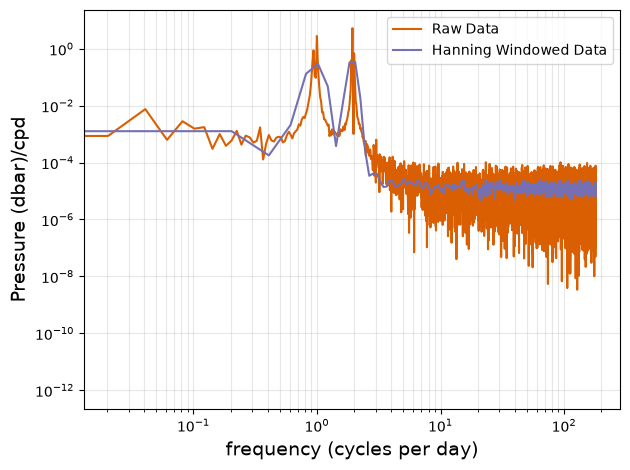

In [119]:
fig, ax = plt.subplots()
ax.loglog(f, amp, color = "#d95f02", label = "Raw Data")
ax.loglog(fbv, Sc, color = "#7570b3", label = "Hanning Windowed Data")
ax.grid(True, which='both', alpha=0.3)
ax.set_ylabel('Pressure (dbar)/cpd', fontsize=14)
ax.set_xlabel('frequency (cycles per day)', fontsize=14)
ax.legend()
plt.tight_layout()
plt.show()

In [120]:
v0 = np.mean(deP**2)
print(f'variance of the record = {v0:.6e}')
print(f'integral, 1 segment = {np.sum(amp)*(1/(dt*N)):.6e} ratio {np.sum(amp)*(1/(dt*N))/v0:.4f}')
print(f'integral, Hanning + sqrt(8/3) = {np.sum(Sc)*(1/(dt*p)):.6e} ratio {np.sum(Sc)*(1/(dt*p))/v0:.4f}')

variance of the record = 2.415057e-01
integral, 1 segment = 2.415059e-01 ratio 1.0000
integral, Hanning + sqrt(8/3) = 2.467329e-01 ratio 1.0216


This is correctly normalized for the Hanning window (about 2% off from what the ratio should be, which is one). 

# Question 2

Fast-sampling frequencies

In [ ]:
freq_f = 1/0.99349
nyq_f = freq_f/2 #half sampling frequency

Science frequency

In [122]:
freq_s = 1/20.86455
nyq_s = freq_s/2 #half sampling frequency

In [141]:
tides = {
    'S1': 24.00,
    '2N2': 12.9054,
    'N2': 12.6583,
    'M2': 12.4206,
    'S2': 12.00,
    'K2': 11.9672
}

orbits = {
    'Fast-sampling': 0.99349,
    'Science': 20.86455
}

def alias_frequency(f_signal, f_sample):
    """Frequency a signal aliases to, given a sampling frequency.
    Returns (f_alias, M) where M is the fold number. Same units in, same out.
    """
    f_ny = f_sample/2
    M = int(np.floor(f_signal/f_ny))
    d = f_signal - M*f_ny
    f_alias = f_ny - d if M % 2 == 1 else d
    return f_alias, M
rows = []
for symbol, T_hr in tides.items():
    f_true = 24.0 / T_hr
    row = {'Symbol': symbol, 'Period_hr': T_hr, 'f_true': f_true}
    for orbit_name, dt_days in orbits.items():
        fs = 1.0 / dt_days
        f_alias, M = alias_frequency(f_true, fs)
        row[f'{orbit_name}_f_alias'] = f_alias
        row[f'{orbit_name}_T_alias'] = 1.0 / f_alias
        row[f'{orbit_name}_M'] = M
    rows.append(row)

df = pd.DataFrame(rows)
print(df.to_string(index=False))

Symbol  Period_hr   f_true  Fast-sampling_f_alias  Fast-sampling_T_alias  Fast-sampling_M  Science_f_alias  Science_T_alias  Science_M
    S1    24.0000 1.000000               0.006553             152.609831                1         0.006492       154.038760         41
   2N2    12.9054 1.859687               0.153419               6.518111                3         0.009513       105.124293         77
    N2    12.6583 1.895989               0.117116               8.538534                3         0.021138        47.307755         79
    M2    12.4206 1.932274               0.080832              12.371413                3         0.015146        66.022172         80
    S2    12.0000 2.000000               0.013105              76.304916                3         0.012984        77.019380         83
    K2    11.9672 2.005482               0.007624             131.170493                3         0.007502       133.296094         83


This shows how the tidal frequencies will be aliased.

In [134]:
names = list(tides.keys())

for orbit, dt in orbits.items():
    f_alias = np.array([alias_frequency(24.0 / period, 1.0 / dt)[0] for period in tides.values()])

    idx = np.argsort(f_alias)
    diffs = np.diff(f_alias[idx])
    min_i = np.argmin(diffs)
    t_min = 1.0 / diffs[min_i]
    
    print(f"=== {orbit} Orbit ===")
    for name, fa in zip(names, f_alias):
        print(f"  {name:3s}: {fa:.6f} cpd  (T = {1/fa:6.2f} d)")
    print(f"Min duration: {t_min:.1f} days ({t_min/365.25:.2f} yrs) — limited by {names[idx[min_i]]} & {names[idx[min_i+1]]}\n")

=== Fast-sampling Orbit ===
  S1 : 0.006553 cpd  (T = 152.61 d)
  2N2: 0.153419 cpd  (T =   6.52 d)
  N2 : 0.117116 cpd  (T =   8.54 d)
  M2 : 0.080832 cpd  (T =  12.37 d)
  S2 : 0.013105 cpd  (T =  76.30 d)
  K2 : 0.007624 cpd  (T = 131.17 d)
Min duration: 933.7 days (2.56 yrs) — limited by S1 & K2

=== Science Orbit ===
  S1 : 0.006492 cpd  (T = 154.04 d)
  2N2: 0.009513 cpd  (T = 105.12 d)
  N2 : 0.021138 cpd  (T =  47.31 d)
  M2 : 0.015146 cpd  (T =  66.02 d)
  S2 : 0.012984 cpd  (T =  77.02 d)
  K2 : 0.007502 cpd  (T = 133.30 d)
Min duration: 989.9 days (2.71 yrs) — limited by S1 & K2



Using the idea that frequencies need to have at least 1/(frequency difference) to be resolved, we find that S1 and K2 have pretty similar periods and will require a long time to be resolved. For the fast-sampling orbit, this is 934 days, while for the science orbit, the time duration must be at least 990 days.

# Question 3

## a

In [ ]:
@dataclass
class WindData:
    dnum: np.ndarray          # times in julian time
    wspeed: np.ndarray   # m/s
    zwind: np.ndarray      # m/s
    mwind: np.ndarray  #m/s

    def __len__(self):
        return len(self.dnum)
    
def get_wind(file):
    """Return different types of wind speed measures from buoy measures.

    Parameters
    ----------
    file : str, optional
        Path to the netCDF file. 

    Returns
    -------
    wind : WindData
    """

    nc = Dataset(file)
    try:
        #fill_value = 9.969209968386869e36 #have to convert from julian date formatting to standard datetime
        #time_data = np.where(nc["TIME"] == fill_value, np.nan, nc["TIME"])
        #time_d = pd.to_datetime(time_data, unit="D", origin = "1950-01-01 00:00:00")
        #dnum = np.array(time_d.values)#.astype('datetime64[m]')
        dnum = np.ndarray.flatten(np.asarray(nc.variables['TIME'][:]))
        wspeed = np.ndarray.flatten(np.asarray(nc.variables['WSPD'][:]))
        zwind = np.ndarray.flatten(np.asarray(nc.variables['UWND'][:]))
        mwind = np.ndarray.flatten(np.asarray(nc.variables['VWND'][:]))

        #process and interpolate in advance
        nand = np.where(wspeed == -999.0, np.nan, wspeed)
        da = xr.DataArray(nand, dims="ws")

        filled_da = da.interpolate_na(dim="ws", method="linear")
        cleaned_np_array = filled_da.values
        if np.isnan(cleaned_np_array).any():
            dnum = dnum[0:47581]
            cleaned_np_array = cleaned_np_array[0:47581]
        wspeed = cleaned_np_array

        nand = np.where(zwind == -999.0, np.nan, zwind)
        da = xr.DataArray(nand, dims="ws")

        filled_da = da.interpolate_na(dim="ws", method="linear")
        cleaned_np_array = filled_da.values
        if np.isnan(cleaned_np_array).any():
            cleaned_np_array = cleaned_np_array[0:47581]
        zwind = cleaned_np_array


        nand = np.where(mwind == -999.0, np.nan, mwind)
        da = xr.DataArray(nand, dims="ws")
        
        filled_da = da.interpolate_na(dim="ws", method="linear")
        cleaned_np_array = filled_da.values
        if np.isnan(cleaned_np_array).any():
            cleaned_np_array = cleaned_np_array[0:47581]
        mwind = cleaned_np_array

    finally:
        nc.close()

    i1 = np.ones(dnum.shape, dtype=bool)

    return WindData(dnum=dnum[i1][:],
                    wspeed=wspeed[i1][:],
                    zwind=zwind[i1][:],
                    mwind = mwind[i1][:])

In [ ]:
w2015 = get_wind("../HW5_data/OS_T8S110W_DM134A-20150425_D_WIND_10min.nc")
w2016 = get_wind("../HW5_data/OS_T8S110W_DM183A-20160321_D_WIND_10min.nc")
w2017 = get_wind("../HW5_data/OS_T8S110W_DM231A-20170606_D_WIND_10min.nc")

In [ ]:
def segmenter(x, window=8640, step =4320): #got numbers by converting 30 and 60 days into number of data points
    arr = np.lib.stride_tricks.sliding_window_view(x, window_shape=window)[::step]
    return arr

In [ ]:
s15d = segmenter(w2015.dnum)
s15w = segmenter(detrend(w2015.wspeed))

s16d = segmenter(w2016.dnum)
s16w = segmenter(detrend(w2016.wspeed))

s17d = segmenter(w2017.dnum)
s17w = segmenter(detrend(w2017.wspeed))

In [ ]:
full_w = np.vstack([s15w, s16w, s17w])

In [ ]:
dt = 10/(60*24)
fn = 1/2/dt
p = len(s15d[0])
fbv = np.arange(0, fn + 1/(dt*p)/2, 1/(dt*p))

In [ ]:
sub15d = s15d[:, ::40]
sub15w = s15w[:, ::40]

sub16d = s16d[:, ::40]
sub16w = s16w[:, ::40]

sub17d = s17d[:, ::40]
sub17w = s17w[:, ::40]

In [ ]:
sub_w = np.vstack([sub15w, sub16w, sub17w])

In [ ]:
dt_full = 10.0 / (60.0 * 24.0)
dt_sub = 40.0 * dt_full 

In [ ]:
def spec(seg, dt):
    n_seg, N = seg.shape
    det = detrend(seg, axis = 1)
    p = len(seg[0])
    fs = 1.0 / dt
    fn = 1.0 / (2.0 * dt)

    win = np.hanning(N)
    win_norm = np.sum(win**2)
    segs_win = det * win
    fbv = np.arange(0, fn + 1/(dt*p)/2, 1/(dt*p))
    fft_vals = np.fft.fft(segs_win, axis=1)[:, :p // 2 + 1]
    psd = (np.abs(fft_vals)**2) / (fs * win_norm)
    psd[:, 1:-1] *= 2
    if N % 2 != 0:
        psd[:, -1] *= 2
        
    
    return fbv, np.mean(psd, axis=0)

In [ ]:
f_full, amp_f = spec(full_w, dt_full)
f_sub, amp_s = spec(sub_w, dt_sub)

## b

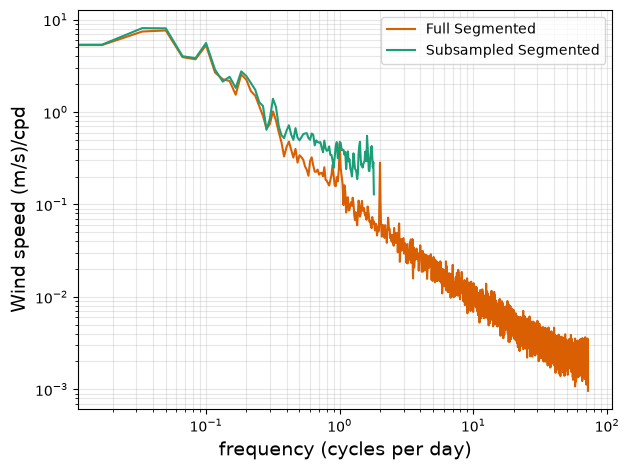

In [ ]:
fig, ax = plt.subplots()
ax.loglog(f_full, amp_f, color = "#d95f02", label = "Full Segmented")
ax.loglog(f_sub, amp_s, color = "#1b9e77", label = "Subsampled Segmented")
ax.grid(True, which='both', alpha=0.3)
ax.set_ylabel('Wind speed (m/s)/cpd', fontsize=14)
ax.set_xlabel('frequency (cycles per day)', fontsize=14)
ax.legend()
plt.tight_layout()
plt.show()

The full data has a much wider set of frequencies. The subsampled stops at a smaller number of cycles per day.

## c

In [ ]:
res = 1/60
res

In [ ]:
nyq = 1/(2*(6.667/24))
nyq

1.7999100044997751

The frequency resolution is 1/T, which is 1/60. This is the same for both plots. The Nyquist frequency for the subsampled data is much lower than for the full segmented data. It is 1.8 cpd.

## d

The diurnal peak is still at 1 cpd for both spectra. The semi-diurnal peak should have a frequency of 2 cpd, but that is higher than the Nyquist frequency of the subsampled data. From what I understand, the alias frequency should be at the sampling frequency - frequency of choice. This is 2*Nyquist. This means that the aliased frequency is at 1.6 cpd.

## e

In [ ]:
var_full = np.sum(amp_f) * (f_full[1] - f_full[0])
var_sub  = np.sum(amp_s) * (f_sub[1] - f_sub[0])
print(f"Integrated PSD Variance -> Full: {var_full:.4f}, Subsampled: {var_sub:.4f}")


Integrated PSD Variance -> Full: 1.5972, Subsampled: 1.5797


The normalizations are consistent. The spectral energies are consistent far below 1.8 cpd, but they diverge as the frequencies approach that value. The reason they diverge is because of the aliasing with the subsambled data. It raises the spectral energy.